# PET lab: MiniPET




In [2]:
### colab setup ###

!pip install -q "https://github.com/conda-incubator/condacolab/archive/main.zip"

import condacolab
condacolab.install(
    python_version="3.13",
    dependencies={"parallelproj": "==2.0.2"},
)

RuntimeError: This module must ONLY run as part of a Colab notebook!

Running this first cell takes some time and you will get an error saying "your session crashed, restarting automatically". **This is fine**, you don't have to run this cell again, you can just move on to the next one.

In [3]:
import os, urllib.request
BASE = "https://raw.githubusercontent.com/debienicolas/minipet/main/"
FILES = ["minipet.py", "petlab.py", "minipet_projector.py","coincCalibMeas.csp.csv"]
for f in FILES:
    if not os.path.exists(f):
        urllib.request.urlretrieve(BASE + f, f)

# look at the files and check if the 3 FILES have been added (this might take a few seconds)

#!pip install h5py nibabel

In [2]:
import glob
import numpy as np
import matplotlib.pyplot as plt

import petlab
import minipet_projector as mpp
from minipet import CSPFile, SLMFile, CLMFile, LOR3DFile
from minipet import N_MODULES, N_PAIRS, N_SIDE, COINC_PAIRS

In [3]:
from scipy.interpolate import UnivariateSpline


In [4]:
from minipet import CLMFile
RUN = 'pointken_260929-102942'
clm = CLMFile('pointken_260929-102942.clm.lr5')
coinc = clm.coincidences()                 # prompts + delayed
prompts = clm.coincidences(delayed=False) 
delayed = clm.coincidences(delayed=True)
times = clm.prompt_times()                 # clock ticks of T_CLK_NS
pairs = clm.pair_index(prompts)            # P0..P17 indices
clm.duration_s # Acquisition time for the CLM file in minutes



357.890273907099

In [6]:
idx_per_s = 242923/357.890273907099
idx_per_05 = idx_per_s * 0.5
idx_per_05
# Divide coinc array into bins of size idx_per_05 to get the number of events in 0.5 seconds
coinc_array_divided = np.array_split(coinc, int(len(coinc)/idx_per_05))

In [ ]:

coinc_array_divided[0]

array([( 301966643,  0, 157, 249,  53,  7,  73, 126,  53, False),
       ( 308403551,  7, 226,  81, 125,  1, 181, 180,  76, False),
       ( 310545298,  9,  33,  78, 122,  4,   6,  48,  43, False),
       ( 310639514,  6,  39, 140,  90, 11, 165,  71,  70, False),
       ( 310834052, 11,  38, 152, 106,  5,  81, 188,  98, False),
       ( 316487888,  2,  85,  89, 109,  8,  96,  71,  59, False),
       ( 329566790,  1,  37,  50, 107,  6, 120,  77,  69, False),
       ( 331375077,  3,  19, 142,  22,  8, 202,  67,  54, False),
       ( 331880286,  5,  43, 188,  61,  0,   5, 173,  33, False),
       ( 334833569,  3,   9, 242, 152,  8,  64, 185,  22, False),
       ( 335015261,  0, 107, 202,  62,  7, 204, 210,  59, False),
       ( 336600269,  9, 188,  62, 127,  2,  24,  22,  21, False),
       ( 341014692,  0, 243, 122,   9,  6, 246, 174, 144, False),
       ( 342785419,  0,   6, 170,  20,  6,  92, 129, 149, False),
       ( 343293843,  1,   5, 103,  73,  8, 207,  69,  69, False),
       ( 3

In [7]:
# approximately how many arrays there should be in the coinc_array_divided list
len(coinc)/idx_per_05

715.780547814198

In [8]:
len(coinc_array_divided)

715

In [9]:
lors = [LOR3DFile(p) for p in sorted(glob.glob(f'{RUN}.3dlor.lr5'))]


[LOR3DFile('pointken_260929-102942.3dlor.lr5')]

In [23]:
print(coinc.shape) #total amt of coincidences
prompts.shape[0] + delayed.shape[0] # Only work with the prompts

(242923,)


242923

In [ ]:
# Create 2D array and assign prompts to the events
prompts

array([(   301966643, 0, 157, 249,  53,  7,  73, 126,  53, False),
       (   308403551, 7, 226,  81, 125,  1, 181, 180,  76, False),
       (   310545298, 9,  33,  78, 122,  4,   6,  48,  43, False), ...,
       (536865910558, 4, 189,   2,  57,  9, 113,   1,  10, False),
       (536868791099, 1, 134,  34,  91,  7, 197,  44, 127, False),
       (536869093940, 4, 212, 194, 107, 10,  88, 145,  97, False)],
      shape=(241686,), dtype=[('t', '<i8'), ('module1', 'u1'), ('x1', 'u1'), ('y1', 'u1'), ('energy1', 'u1'), ('module2', 'u1'), ('x2', 'u1'), ('y2', 'u1'), ('energy2', 'u1'), ('delayed', '?')])

In [24]:
import numpy as np
# In unit of the t_clk
t_clk = 0.5

(times[-1]- times[0])*t_clk/(6*60)

np.float64(745232121.2458333)

In [25]:
from parallelproj.unlist import regular_polygon_events_to_sinogram

In [27]:
geom_bundle = mpp.build_sinogram_projector()
sinogram = regular_polygon_events_to_sinogram(prompts, geom_bundle)

TypeError: regular_polygon_events_to_sinogram() missing 3 required positional arguments: 'r_red', 'd_blue', and 'r_blue'

C:\Users\Ines\AppData\Local\Temp\ipykernel_38212\1825440752.py:13: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()
C:\Users\Ines\AppData\Local\Temp\ipykernel_38212\1825440752.py:24: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


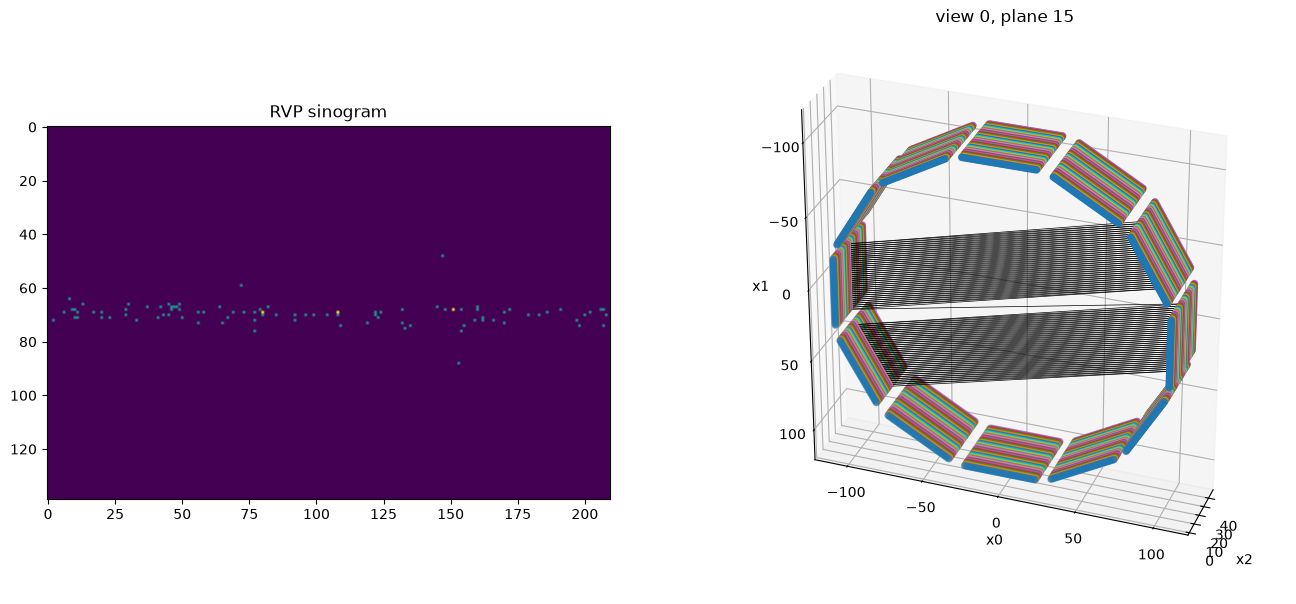

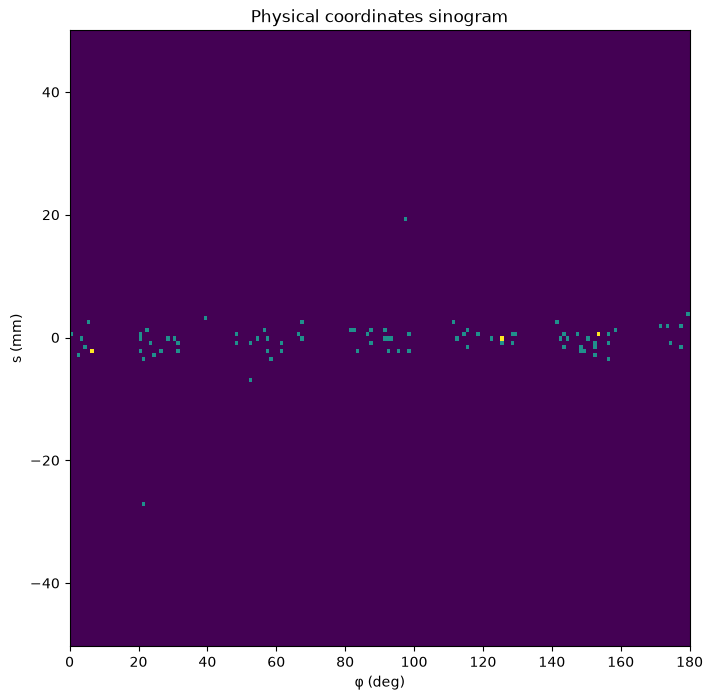

In [24]:
# converting 3D lor to RVP sinogram
geom_bundle = mpp.build_sinogram_projector()
y_rvp = mpp.lors_to_sinogram(*lors[0].crystal_pairs()) # converts the first 3dlor file to an RVP sinogram

fig = plt.figure(figsize=(16,8))
ax1 = fig.add_subplot(121)
# plot the 16th plane of the sinogram in RVP format
ax1.imshow(y_rvp[...,15])
ax1.set_title('RVP sinogram')
ax2 = fig.add_subplot(122, projection="3d")
view, plane = 0,15
mpp.show_lordesc_view(ax2,view, plane, geom_bundle.lor_descriptor)
fig.show()


# converting RVP sinogram to physical coordinates
coords = mpp.sinogram_coords()
y_coords = mpp.rebin_phi_s(y_rvp[...,49], coords)
# plot the plane 16 sinogram in physical coordinates
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111)
mpp.show_sino(ax, y_coords)
ax.set_title('Physical coordinates sinogram')
fig.show()



Calculate Features from Sinogram

In [46]:
y_rvp.shape

(139, 210, 1225)

In [151]:
# Average Pixel Values of the RVP sinogram
avg_pixel_values = np.mean(y_rvp, axis=(0, 1)) # average pixel values across the axes of the sinogram
min_pixel_values = np.min(y_rvp, axis=(0, 1))
max_pixel_values = np.max(y_rvp, axis=(0, 1))
# Center of mass is calculated as the weighted average of the pixel values, where weights
# are the pixel indices. The center of mass gives an indication of the distribution of pixel values in the sinogram.

#center_of_mass_1 is calculated as the weighted average of the average pixel values across the sinogram, where weights are the pixel indices. This gives a measure of the distribution of pixel values in the sinogram.
center_of_mass_1 = np.sum(avg_pixel_values * np.arange(avg_pixel_values.size)) / np.sum(avg_pixel_values)
#center_of_mass_2 is calculated as the weighted average of the pixel values across the entire sinogram, where weights are the pixel indices. This gives a more comprehensive measure of the distribution of pixel values in the sinogram.
center_of_mass_2 = np.sum(y_rvp * np.arange(y_rvp.shape[0])[:, None, None], axis=0) / np.sum(y_rvp, axis=0)


center_of_mass_3 = np.array([np.sum(np.arange(y_rvp.shape[0]) * np.sum(y_rvp, axis=(1, 2))) / np.sum(y_rvp),
                               np.sum(np.arange(y_rvp.shape[1]) * np.sum(y_rvp, axis=(0, 2))) / np.sum(y_rvp)])
print(center_of_mass_3)


[ 69.94866251 104.50553316]


C:\Users\Ines\AppData\Local\Temp\ipykernel_38212\502107551.py:11: RuntimeWarning: divide by zero encountered in divide
  center_of_mass_2 = np.sum(y_rvp * np.arange(y_rvp.shape[0])[:, None, None], axis=0) / np.sum(y_rvp, axis=0)
C:\Users\Ines\AppData\Local\Temp\ipykernel_38212\502107551.py:11: RuntimeWarning: invalid value encountered in divide
  center_of_mass_2 = np.sum(y_rvp * np.arange(y_rvp.shape[0])[:, None, None], axis=0) / np.sum(y_rvp, axis=0)


In [ ]:
np.sum(y_rvp, axis=(1, 2)) # takes sum of the pixel values across the axes of the sinogram, resulting in a 1D array representing the total pixel values for each plane of the sinogram. This can be used to analyze the distribution of pixel values across the planes of the sinogram.


array([4.000e+00, 1.000e+00, 0.000e+00, 1.000e+00, 1.000e+00, 1.000e+01,
       7.000e+00, 1.000e+01, 9.000e+00, 5.000e+00, 1.000e+00, 8.000e+00,
       7.000e+00, 6.000e+00, 3.000e+00, 1.000e+01, 6.000e+00, 1.500e+01,
       1.800e+01, 1.500e+01, 1.500e+01, 1.600e+01, 1.900e+01, 1.800e+01,
       5.000e+00, 2.200e+01, 2.300e+01, 1.900e+01, 2.100e+01, 2.300e+01,
       2.100e+01, 1.500e+01, 2.700e+01, 1.800e+01, 2.400e+01, 4.200e+01,
       2.500e+01, 3.500e+01, 2.900e+01, 2.900e+01, 1.400e+01, 3.300e+01,
       4.000e+01, 3.200e+01, 2.900e+01, 3.800e+01, 4.200e+01, 3.800e+01,
       4.300e+01, 3.100e+01, 3.700e+01, 3.000e+01, 3.300e+01, 2.700e+01,
       3.600e+01, 3.300e+01, 4.100e+01, 3.900e+01, 5.900e+01, 5.900e+01,
       8.400e+01, 1.420e+02, 1.950e+02, 4.100e+02, 8.110e+02, 1.722e+03,
       2.687e+03, 3.703e+03, 5.672e+03, 7.385e+03, 7.405e+03, 6.003e+03,
       5.289e+03, 4.534e+03, 2.931e+03, 1.526e+03, 7.640e+02, 3.750e+02,
       1.920e+02, 1.070e+02, 7.200e+01, 6.600e+01, 

## Part 5: Reconstruction and PSF

**Q10** Compare the source positions from the image with those you estimated from the sinogram.
**Q11** Report the radial, tangential and axial FWHM of the sources in a table. Which direction
degrades off-centre, and why?
**Q12** Compare your FWHM with the FWHM from the Moses equation [Mos11]. Discuss.

**Given**
- `grid = petlab.ImageGrid()`: a voxel grid centred on the scanner, where you define the
  `grid.shape`, `grid.voxel`, with axis (x, y, z).
- `P = mpp.projector(grid)`: the `parallelproj` projector. `P(x)` is the forward projection of an
  image into a `(139, 210, 1225)` sinogram, `P.adjoint(y)` the back projection.
- `sens = mpp.sensitivity_image(grid)`: the sensitivity σ_j = Σ_i a_ij, i.e. `P.adjoint` of a
  sinogram of ones over all measured LORs.

MLEM is then

$$x_j^{(n+1)} = \frac{x_j^{(n)}}{\sigma_j}\sum_i a_{ij}\frac{y_i}{\sum_k a_{ik}x_k^{(n)} + \bar r_i}$$

which is four lines with `P` and `P.adjoint`. You can put the randoms of Part 3 in the forward model $\bar{r}_i$




In [50]:
grid = petlab.ImageGrid(
  # set voxel size in mm: voxel_mm = (...,...,...)
  voxel_mm = [1,1,1],
  fov_mm = [40, 40, 40]
  # set the image dim in mm: fov_mm = (...,...,...)
)

grid = petlab.ImageGrid() # automatically sets the params

def mlem(y, grid, n_iter=10, r=None):
  bins = np.flatnonzero(y)
  A = mpp.BinProjector(bins, grid)
  sens = mpp.sensitivity_image(grid)

  y_sub = y.ravel()[bins]
  r_sub = r.ravel()[bins] if r is not None else None

  x = np.ones(grid.shape, np.float32)
  for iter in range(n_iter):
    ybar = A.fwd(x) if r_sub is None else A.fwd(x) + r_sub
    x *= A.back(y_sub / np.maximum(ybar, 1e-6)) / np.maximum(sens, 1e-6)
  return x

x = mlem(y_rvp, grid, n_iter=10)


computing the sensitivity image (once, then cached) ...


In [59]:
x.shape

(250, 250, 70)

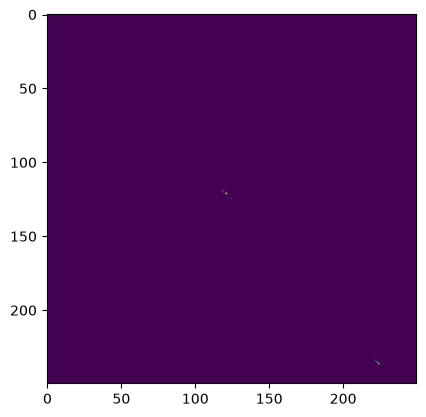

In [92]:
plt.imshow(x[:,:,38]) # [x, y, z]


2.015594e+13
5


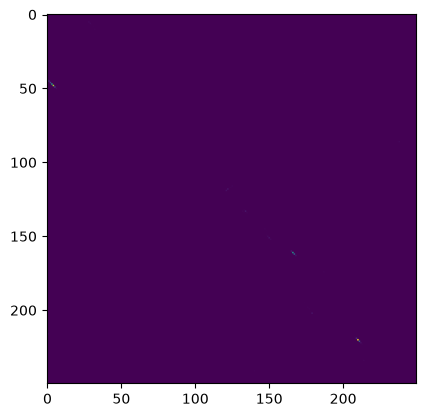

In [51]:
# plot the sensitivity image, both an axial and transaxial slice. What does this show you?
# This shows us the transaxial slice

x[:,:,25] # average along z and see the max and take the FWHM 

max = 0
idx = 0
for i in range(70):
    sum = x[:,:,i].sum()
    if(sum>max):
        max = sum
        idx = i
    
print(sum)
print(idx)
plt.imshow(x[:,:,32]) # [x, y, z]
# Found the maximum and then get the FWHM here



In [277]:
x.shape

(250, 250, 70)

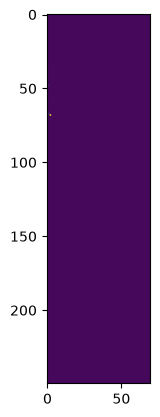

In [136]:
plt.imshow(x[3,:,:]) # x-z plane

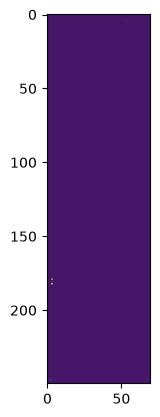

In [149]:
plt.imshow(x[:,23,:]) # y-z

In [ ]:
# Q10-Q12: your code here
